In [4]:
# --- bootstrap: dodaj katalog projektu do sys.path (dziala z notebooks/ i z root) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while not (_p / 'config.py').exists() and _p != _p.parent:
    _p = _p.parent
if str(_p) not in sys.path:
    sys.path.insert(0, str(_p))
from IPython.display import display

import config


# Notebook 01b: model tematyczny (BERTopic)

Etap buduje model tematyczny na całym korpusie: stroi parametry UMAP, HDBSCAN i wektoryzatora, scala tematy hierarchicznie i zapisuje oba modele - podstawowy i scalony.

Wejście: `data/dane_z_prawdopodobienstwem.csv` z notebooka `01a`.
Wyjście: `models/best_bertopic_model/`, `models/bertopic_model_merged/`, `models/best_bertopic_model_reduced/` oraz rysunek w `outputs/figures/`.

Logika siedzi w `src/topics.py`, notebook ją wywołuje i pokazuje wyniki. Spójność tematów liczy jeden kod dla wszystkich modeli - `src/utils.py`, oparty na gensimie - żeby BERTopic, LDA i NMF dawały się porównać tą samą miarą na tym samym korpusie referencyjnym.

Strojenie i budowa modelu wymagają GPU i trwają godzinami, dlatego Optuna domyślnie wczytuje istniejące próby z bazy bez liczenia czegokolwiek.

## 1. Korpus i komponenty

Embeddingi liczone są raz i podawane do każdego kolejnego kroku. Powtórne liczenie ich w pętli strojenia byłoby najdroższą częścią przebiegu, a wynik nie zależy od strojonych parametrów.

In [5]:
import torch

from src import topics as tpx
from src.evaluation import load_predictions

print(f"CUDA: {torch.cuda.is_available()}"
      + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))

df = load_predictions()
texts = df["text"].astype(str).str.lower().tolist()
print(f"Nagłówków do modelowania: {len(texts)}")

tokenizer, embedding_model, ctfidf_model, representation_model = tpx.build_components()
embeddings = embedding_model.encode(texts, show_progress_bar=True)
print(f"Embeddingi: {embeddings.shape}")

CUDA: True (NVIDIA GeForce RTX 4060 Ti)
Nagłówków do modelowania: 55914


Some weights of the model checkpoint at allegro/herbert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.sso.sso_relationship.bias', 'cls.sso.sso_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Batches: 100%|██████████| 1748/1748 [00:32<00:00, 53.05it/s]


Embeddingi: (55914, 768)


## 2. Strojenie parametrów

Kryterium jest NPMI, czyli spójność tematów. Udział obserwacji odstających jest zapisywany przy każdej próbie, ale nie wchodzi do funkcji celu - karanie za outliery popycha HDBSCAN do wciągania do tematów nagłówków, które do nich nie należą.

`OPTUNA_TRIALS = 0` wczytuje istniejące próby z bazy bez liczenia czegokolwiek.

In [6]:
import optuna

OPTUNA_TRIALS = 0

objective = tpx.make_objective(texts, embeddings, tokenizer, embedding_model,
                               ctfidf_model, representation_model)
study = optuna.create_study(
    study_name="bertopic_npmi",
    storage=config.BERTOPIC_OPTUNA_DB,
    load_if_exists=True,
    direction="maximize",
)
study.optimize(objective, n_trials=OPTUNA_TRIALS)

params = tpx.best_params_from_study(study)
proba = study.best_trial
print(f"Próba #{proba.number}: NPMI={proba.value:.4f}, "
      f"outliery={proba.user_attrs.get('outlier_ratio', float('nan')):.3f}, "
      f"tematy={proba.user_attrs.get('n_topics')}")
for klucz, wartosc in params.items():
    print(f"  {klucz} = {wartosc}")

[I 2026-10-16 19:33:33,585] Using an existing study with name 'bertopic_npmi' instead of creating a new one.


Próba #499: NPMI=0.2008, outliery=0.726, tematy=53
  n_neighbors = 45
  n_components = 5
  metric_umap = cosine
  min_dist = 0.09585362686709284
  min_cluster_size = 65
  metric_hdbscan = euclidean
  cluster_selection_method = eom
  ngram_range = 3
  min_df = 2
  max_df = 0.9412562490903456


## 2a. Udział obserwacji odstających a próg wielkości skupiska

Wysokiego udziału obserwacji odstających nie zbija sam `min_cluster_size`. Zestawienie liczy to z bazy prób: ile prób było użytecznych, w jakim przedziale mieszczą się udziały i jak udział zmienia się z progiem. Próby o liczbie tematów poniżej `MIN_TOPICS` funkcja celu odrzuca i do zestawienia nie wchodzą.

In [ ]:
tabela_odstajacych, podsumowanie_odstajacych = tpx.outlier_share_by_cluster_size(study)

print(f"Próby użyteczne: {podsumowanie_odstajacych['proby_uzyteczne']}, "
      f"odrzucone progiem liczby tematów: {podsumowanie_odstajacych['proby_odrzucone']}")
print(f"Udział odstających: {podsumowanie_odstajacych['udzial_min']:.3f} - "
      f"{podsumowanie_odstajacych['udzial_max']:.3f}")
print(f"Korelacja udziału z min_cluster_size: "
      f"{podsumowanie_odstajacych['korelacja_z_progiem']:+.3f}")
display(tabela_odstajacych)

## 3. Model podstawowy

Filtry `min_df` i `max_df` nakładane są dopiero po wyznaczeniu tematów, przez `update_topics`. Nałożone od razu odrzuciłyby część słownika jeszcze przed klastrowaniem, a przy ostrym progu wektoryzator kończy się błędem na pustym słowniku. Kolejność jest ta sama co w funkcji celu, więc model finalny powstaje w warunkach, w których był oceniany.

In [7]:
topic_model = tpx.build_final_model(
    params, texts, embeddings, tokenizer, embedding_model, representation_model,
)
print(f"Tematów: {len(topic_model.get_topic_info()) - 1}")
topic_model.get_topic_info().head(15)

Zapisano model -> models/best_bertopic_model
Tematów: 53


,Topic,Count,Name,Representation,Representative_Docs
0,-1,40591,-1_tuska_czy_a_polska,"[tuska, czy, a, polska, rząd, prezydent, poseł...",[wyborcze przepychanki w koalicji 13 grudnia. ...
1,0,1434,0_izrael_rosjanie_rosja_atak,"[izrael, rosjanie, rosja, atak, donbasie, w do...",[nocny atak rosji na odessę. sześć osób rannyc...
2,1,1292,1_sondaż_sondaż czy_polacy_sondaż polacy,"[sondaż, sondaż czy, polacy, sondaż polacy, so...",[sondaż: jak polacy oceniają wykorzystanie śro...
3,2,1189,2_tusk_tusk o_tusk w_tusk chce,"[tusk, tusk o, tusk w, tusk chce, memy tusk, t...",[tusk i jego świta zaatakowali morawieckiego z...
4,3,1082,3_neo_sędzia_prokuratura_sąd,"[neo, sędzia, prokuratura, sąd, sędziów, sn, s...",[jest zawiadomienie do prokuratury na szefową ...
5,4,924,4_donald_donald tusk_donalda_tusk,"[donald, donald tusk, donalda, tusk, donalda t...","[„witam z powrotem” – donald tusk w brukseli, ..."
6,5,577,5_duda_prezydent duda_andrzej duda_andrzej,"[duda, prezydent duda, andrzej duda, andrzej, ...",[andrzej duda rozmawiał z prezydentem - elekte...
7,6,569,6_a_budka_zobacz_memy,"[a, budka, zobacz, memy, zobacz memy, wideo, a...","[myrcha chwali się, że przebiegł 5,19 km. kome..."
8,7,449,7_kaczyński_kaczyński o_kaczyński w_kaczyński ...,"[kaczyński, kaczyński o, kaczyński w, kaczyńsk...",[kaczyński o obronie granicy przed atakiem hyb...
9,8,400,8_niezalezna_niezalezna pl_dla niezalezna_dla ...,"[niezalezna, niezalezna pl, dla niezalezna, dl...","[tomasz łysiak dla niezalezna.pl o ""uchodźczej..."


## 4. Tematyczne punkty odniesienia

LDA i NMF na tym samym korpusie i z tą samą miarą spójności. Porównanie mówi, czy modelowanie na embeddingach kontekstowych daje spójniejsze tematy niż klasyczne modele na zliczeniach.

In [8]:
import pandas as pd

from src.utils import topic_coherences

n_tematow = len([t for t in topic_model.get_topic_info().Topic if t != -1])
porownanie = pd.concat([
    pd.DataFrame([("BERTopic", *topic_coherences(topic_model, texts, tokenizer))],
                 columns=["model", "UMass", "UCI", "NPMI"]),
    tpx.lda_nmf_baselines(texts, tokenizer, n_tematow),
], ignore_index=True)
print(f"Porównanie modeli tematycznych ({n_tematow} tematów, 10 czołowych słów):")
porownanie

Porównanie modeli tematycznych (53 tematów, 10 czołowych słów):


,model,UMass,UCI,NPMI
0,BERTopic,-7.188350,-1.161566,0.200783
1,LDA,-8.886927,-4.046388,-0.140281
2,NMF,-8.636379,-3.328019,-0.054212


## 5. Redukcja obserwacji odstających

`reduce_outliers` przypisuje nagłówki bez tematu do najbliższego tematu według c-TF-IDF. Zabieg podnosi pokrycie korpusu kosztem spójności, dlatego obie wartości podane są przed i po - decyzja o użyciu modelu zredukowanego należy do etapu, który z niego korzysta.

In [9]:
from src.utils import rel

wplyw = tpx.reduce_outliers_compare(topic_model, texts, tokenizer)
display(wplyw)

topic_model.save(str(config.BERTOPIC_REDUCED), serialization="safetensors", save_ctfidf=True)
print(f"Zapisano model po redukcji -> {rel(config.BERTOPIC_REDUCED)}")

2026-10-16 19:39:24,524 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


,etap,outlier_ratio,UMass,UCI,NPMI
0,przed,0.725954,-7.188350,-1.161566,0.200783
1,po,0.000572,-7.447758,-2.517874,-0.020644


Zapisano model po redukcji -> models/best_bertopic_model_reduced


## 6. Scalanie hierarchiczne

HDBSCAN daje tematy drobne i częściowo pokrywające się treścią. Scalanie hierarchiczne łączy je na kolejnych poziomach odległości; dla każdego poziomu liczona jest spójność, a wybór poziomu to kompromis między liczbą tematów a ich spójnością.

Kryterium wyboru jest jawne: suma trzech miar przeskalowanych min-max. Same miary mają różne zakresy i nie dają się dodać wprost. Poziom można też wskazać ręcznie, podając `row`.

Przebieg wymaga głębokiej kopii modelu na każdym poziomie, więc jest kosztowny pamięciowo i trwa kilkadziesiąt minut.

In [10]:
URUCHOM_SCALANIE = True

if URUCHOM_SCALANIE:
    poziomy, hierarchia = tpx.merge_level_search(topic_model, texts, tokenizer)
else:
    import pickle

    with open(config.OUTPUTS_DIR / "merger_optimisation_results.pkl", "rb") as f:
        poziomy = pd.DataFrame(pickle.load(f))
    miary = ["umass", "uci", "npmi"]
    znorm = poziomy[miary].apply(lambda k: (k - k.min()) / (k.max() - k.min()))
    poziomy["sum_normalised"] = znorm.sum(axis=1)
    print(f"Wczytano {len(poziomy)} poziomów z poprzedniego przebiegu.")

poziomy.sort_values("sum_normalised", ascending=False).head(5)

100%|██████████| 52/52 [00:00<00:00, 217.19it/s]


  dystans 0.4555: 52 tematow, NPMI=-0.0205, UMass=-7.465, UCI=-2.527
  dystans 0.4789: 51 tematow, NPMI=-0.0236, UMass=-7.477, UCI=-2.553
  dystans 0.4870: 50 tematow, NPMI=-0.0235, UMass=-7.560, UCI=-2.589
  dystans 0.5151: 49 tematow, NPMI=-0.0207, UMass=-7.503, UCI=-2.535
  dystans 0.5215: 48 tematow, NPMI=-0.0182, UMass=-7.421, UCI=-2.481
  dystans 0.5479: 47 tematow, NPMI=-0.0162, UMass=-7.338, UCI=-2.431
  dystans 0.5583: 46 tematow, NPMI=-0.0158, UMass=-7.402, UCI=-2.460
  dystans 0.5598: 45 tematow, NPMI=-0.0154, UMass=-7.380, UCI=-2.437
  dystans 0.5653: 44 tematow, NPMI=-0.0163, UMass=-7.339, UCI=-2.438
  dystans 0.6029: 43 tematow, NPMI=-0.0146, UMass=-7.296, UCI=-2.402
  dystans 0.6174: 42 tematow, NPMI=-0.0143, UMass=-7.235, UCI=-2.373
  dystans 0.6758: 41 tematow, NPMI=-0.0135, UMass=-7.119, UCI=-2.312
  dystans 0.6831: 40 tematow, NPMI=-0.0148, UMass=-7.002, UCI=-2.273
  dystans 0.7339: 39 tematow, NPMI=-0.0104, UMass=-6.852, UCI=-2.156
  dystans 0.7541: 38 tematow, NPMI

,distance,n_topics,merge_groups,umass,uci,npmi,sum_normalised
32,0.928194,20,"[[0, 2, 4, 6, 10, 22, 32, 36, 39, 40, 45, 47, ...",-5.099565,-0.940253,0.029130,2.157523
51,1.326055,1,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",-2.516325,-0.126856,-0.024576,2.069252
45,1.084115,7,"[[0, 2, 4, 6, 7, 9, 10, 13, 16, 22, 29, 32, 36...",-3.914728,-0.632948,0.002687,2.058964
44,1.055540,8,"[[0, 2, 4, 6, 7, 9, 10, 13, 16, 22, 29, 32, 36...",-3.896313,-0.626131,0.002088,2.055002
46,1.087479,6,"[[5, 8, 12, 17, 21, 23, 24, 25, 26, 27, 33, 34...",-3.677338,-0.523576,-0.003747,2.038936


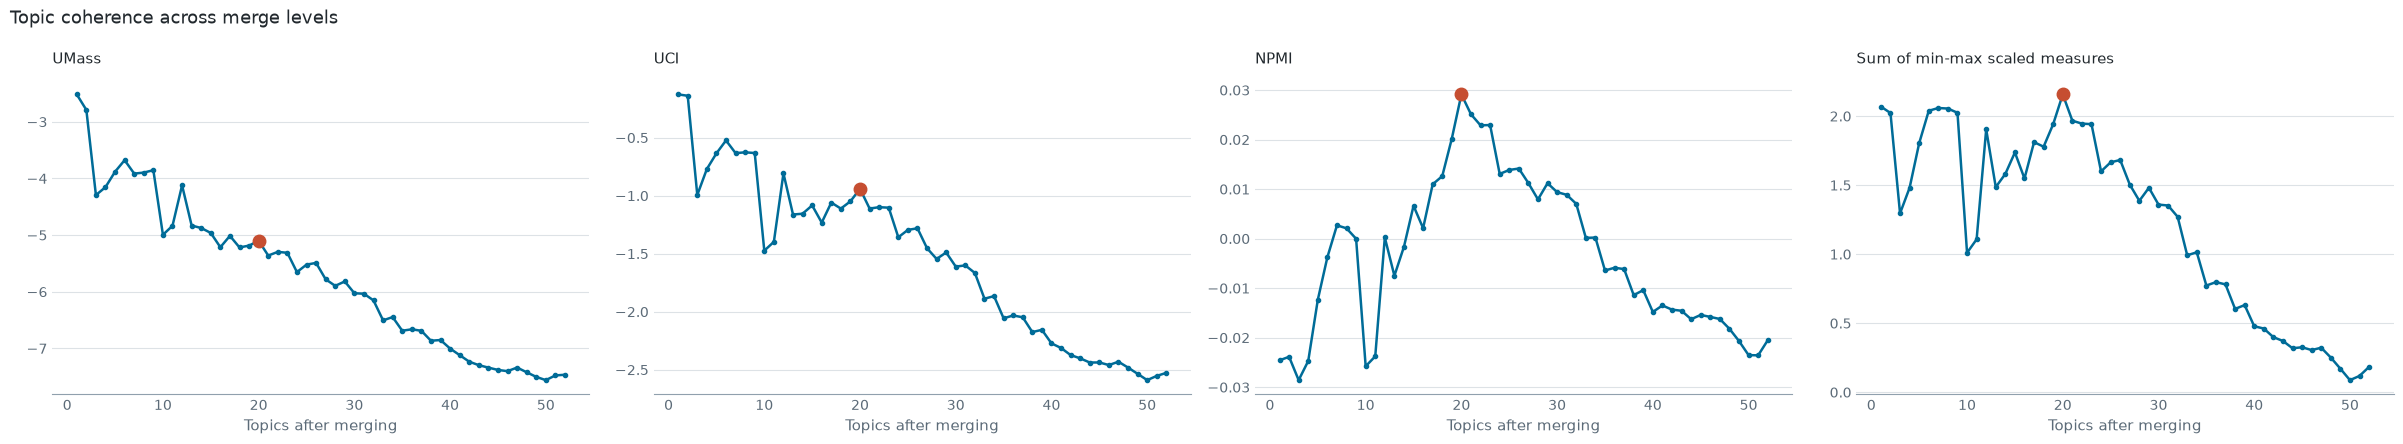

In [11]:
from src.visualization import plot_merge_levels

wybrany = int(poziomy["sum_normalised"].idxmax())
fig = plot_merge_levels(
    poziomy, x="n_topics", highlight=wybrany,
    save_path=config.FIGURES / "09_spojnosc_poziomow_scalania.png",
)

In [12]:
scalony = tpx.apply_merge_level(topic_model, texts, poziomy, row=wybrany)
scalony.get_topic_info().head(10)

Poziom scalania: wiersz 32, dystans 0.9282, 20 tematow, sum_normalised 2.158
Zapisano model scalony -> models/bertopic_model_merged


,Topic,Count,Name,Representation,Representative_Docs
0,-1,32,-1_не_це_польщі_на,"[не, це, польщі, на, як, за, чи, що, про, так]",[щодня в моїй країні росія вбиває людей. ви бі...
1,0,24532,0_na_nie_tusk_się,"[na, nie, tusk, się, to, do, po, tuska, pis, co]",[za tuska nawet... sam tusk wyjechał za granic...
2,1,4653,1_wybory_na_do_pis,"[wybory, na, do, pis, nie, czarzasty, krzyszto...",[wybory prezydenckie 2025. paweł kukiz ocenił ...
3,2,4178,2_bodnar_prokuratura_sąd_neo,"[bodnar, prokuratura, sąd, neo, ziobry, sędzió...","[zawiadomienie do prokuratury na schaba, radzi..."
4,3,3908,3_duda_prezydent_nawrocki_trump,"[duda, prezydent, nawrocki, trump, andrzej, pu...","[prezydent andrzej duda przybył na łotwę, prez..."
5,4,2932,4_morawiecki_premier_do_się,"[morawiecki, premier, do, się, na, nie, mateus...",[premier morawiecki odpowiada na orędzie prezy...
6,5,2923,5_sondaż_polacy_nowy_pis,"[sondaż, polacy, nowy, pis, polaków, ko, proc,...","[nowy sondaż: pis na czele, wzrost poparcia dl..."
7,6,2548,6_kaczyński_jarosław_pis_nie,"[kaczyński, jarosław, pis, nie, na, to, czarne...",[jarosław kaczyński o sprawie pegasusa: naduży...
8,7,2296,7_sejm_ustawy_projekt_ustawa,"[sejm, ustawy, projekt, ustawa, komisji, ds, s...","[pis i konfederacja przeciw, ale... projekt no..."
9,8,1642,8_hołownia_szymon_2050_sejmu,"[hołownia, szymon, 2050, sejmu, nie, marszałek...",[marszałek sejmu szymon hołownia w orędziu: id...


## 7. Porównanie enkoderów

Krok opcjonalny. Surowy HerBERT użyty jest tu jako enkoder zdaniowy, do czego nie był uczony, co może współodpowiadać za wysoki udział obserwacji odstających. Porównanie przelicza tę samą konfigurację na modelach zdaniowych i podaje liczbę tematów, udział odstających oraz spójność.

Każdy kandydat wymaga policzenia embeddingów od nowa, stąd jawne uruchomienie.

In [13]:
URUCHOM_POROWNANIE_ENKODEROW = False

if URUCHOM_POROWNANIE_ENKODEROW:
    display(tpx.compare_embedding_backbones(
        texts, params, tokenizer, representation_model))
else:
    print("Porównanie pominięte. Ustaw URUCHOM_POROWNANIE_ENKODEROW = True, aby je policzyć.")

Porównanie pominięte. Ustaw URUCHOM_POROWNANIE_ENKODEROW = True, aby je policzyć.


## Dalsze etapy

Analiza błędów klasyfikacji korzysta z zapisanych tu modeli:

- `02_topic_model_time_series_analysis.ipynb` - rozkład błędów w czasie według tematu i wydawcy
- `03_misclassified_headlines_analysis.ipynb` - analiza samych pomyłek
- `04_tabele_i_rysunki.ipynb` - tabele i rysunki